# Testing HSA_Cam_B_001_lib.py

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import ICIW_Plots
from ICIW_Plots import make_square_subplots, cm2inch

plt.style.use("ICIWstyle")

In [2]:
from HSA_Cam_B_001_lib import (
    forward_solve,
    vec_forward_solve,
    SIDX,
    PIDX,
    _forward_solve,
    _vec_forward_solve,
    _ODE_func,
    _jitted_forward_solve,
    _jitted_vec_forward_solve,
)

In [3]:
def plot_hydrogenation_results(sol):
    fig = ICIW_Plots.figure(
        layout="double_column",
        height=1.5 * ICIW_Plots.size("ICIW", "double_column", "in"),
    )
    axs = make_square_subplots(
        fig=fig,
        ax_layout=(3, 2),
        ax_width=5.5 * cm2inch,
        h_sep=0.7,
        left_h=1,
        v_sep=0.5,
        sharex=True,
        sharelabel=True,
        xlabel=r"$t$ / $\mathrm{s}$",
        ylabel=[r"$m$ / $\mathrm{kg}$", r"$m$ / $\mathrm{kg}$", r"$a$ / 1"],
    )

    for spec in ["RDY", "RYE", "RYA", "REA", "RDEt"]:
        axs[0, 0].plot(
            sol.t / 60,
            sol.y[SIDX[spec], :].T,
            label=spec,
        )
    axs[0, 0].set_title(r"RDY-RDEt")
    axs[0, 0].legend()
    # axs[0, 1].plot(sol.t / 60, sol.m[4, :])
    # axs[0, 1].plot(sol.t / 60, sol.y[SIDX["RDEt(X)"], :])

    axs[0, 1].plot(sol.t / 60, sol.y[SIDX["dimerA"], :], label="dimerA")
    axs[0, 1].plot(sol.t / 60, sol.y[SIDX["dimerY"], :], label="dimerY")
    axs[0, 1].plot(
        sol.t / 60,
        sol.y[SIDX["dimerA"], :] + sol.y[SIDX["dimerY"], :],
        "k--",
        label="total",
    )
    axs[0, 1].set_title(r"post RDEt products")
    axs[0, 1].legend()

    axs[1, 0].plot(sol.t / 60, sol.y[SIDX["H2"], :], label="(aq)")
    axs[1, 0].plot(sol.t / 60, sol.y[SIDX["conH2[G]"], :], "--", label="cum. (g)")
    axs[1, 0].set_title(r"H_2")
    axs[1, 0].legend()
    axs[1, 1].plot(sol.t / 60, sol.y[SIDX["RDY"], :], label="(aq)")
    axs[1, 1].plot(sol.t / 60, sol.y[SIDX["RDY[S]"], :], "--", label="(s)")
    axs[1, 1].set_title(r"RDY")
    axs[1, 1].legend()

    axs[2, 0].plot(sol.t / 60, sol.y[SIDX["a"], :])
    axs[2, 0].set_title(r"catalyst activity")

    plt.show()

In [4]:
m_li0 = jnp.array(
    [
        0.2574,
        0.194,
        0.0,
        0.00235,
        0.00235,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
    ]
)
p = 10 * 1.01325e5  # Pa
T = 293.15  # K
m_s0 = 0.08784  # kg
k_deact = 1e-4
EA_deact = 50000  # J/mol
deact_order = 1.0

t = jnp.linspace(0, 150 * 60, 100)  # s

In [5]:
y0 = jnp.concatenate((m_li0, jnp.array([m_s0, 0.0, T, 1.0])))
params = jnp.array([p, m_s0, k_deact, EA_deact, deact_order])

In [6]:
from types import SimpleNamespace

sol = SimpleNamespace()
sol.y = _forward_solve(y0, t, params).T
sol.t = t

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


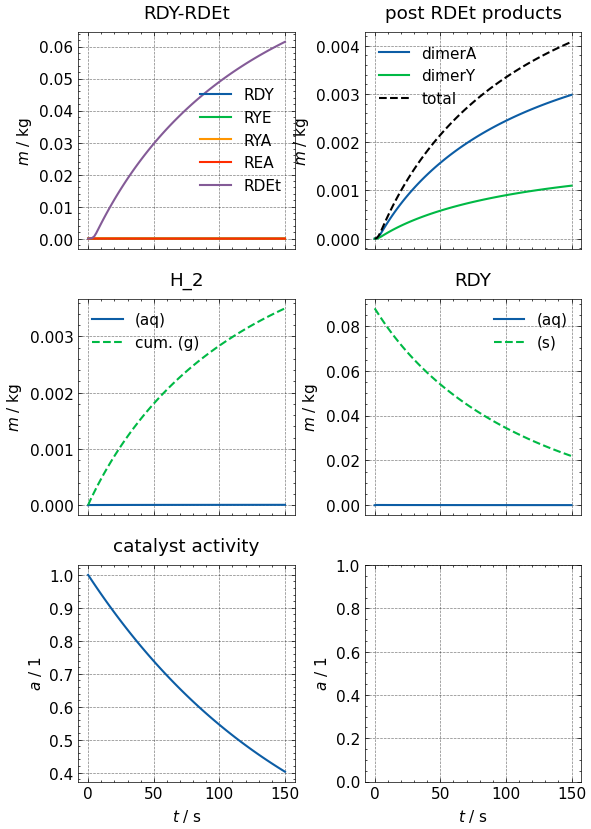

In [7]:
plot_hydrogenation_results(sol)

In [8]:
Ts = jnp.linspace(280, 400, 100)  # K

y0s = jnp.zeros((Ts.shape[0], y0.shape[0]))

y0s = y0s.at[:, 0:14].set(m_li0)
y0s = y0s.at[:, 14].set(m_s0)
y0s = y0s.at[:, 16].set(Ts)
y0s = y0s.at[:, 17].set(1.0)

print(y0s.shape)

paramses = jnp.tile(params, (Ts.shape[0], 1))
print(paramses.shape)

(100, 18)
(100, 5)


In [9]:
jsols = _jitted_vec_forward_solve(y0s, t, paramses)

In [23]:
cust_solve = jax.jit(jax.vmap(_jitted_forward_solve, in_axes=(0, 0, 0)))

In [24]:
cust_solve(y0s, jnp.tile(t, (y0s.shape[0], 1)), paramses)

Array([[[2.57400000e-01, 1.94000000e-01, 0.00000000e+00, ...,
         0.00000000e+00, 2.80000000e+02, 1.00000000e+00],
        [2.57400000e-01, 1.94000000e-01, 5.18344518e-06, ...,
         5.02378000e-05, 2.80000000e+02, 9.96500539e-01],
        [2.57400000e-01, 1.94000000e-01, 5.19558522e-06, ...,
         7.96527139e-05, 2.80000000e+02, 9.93013324e-01],
        ...,
        [2.57400000e-01, 1.94000000e-01, 6.42611800e-06, ...,
         1.92666429e-03, 2.80000000e+02, 7.11739663e-01],
        [2.57400000e-01, 1.94000000e-01, 6.43346992e-06, ...,
         1.93979909e-03, 2.80000000e+02, 7.09248958e-01],
        [2.57400000e-01, 1.94000000e-01, 6.44076186e-06, ...,
         1.95285110e-03, 2.80000000e+02, 7.06766969e-01]],

       [[2.57400000e-01, 1.94000000e-01, 0.00000000e+00, ...,
         0.00000000e+00, 2.81212121e+02, 1.00000000e+00],
        [2.57400000e-01, 1.94000000e-01, 5.05312671e-06, ...,
         5.24736804e-05, 2.81212121e+02, 9.96161762e-01],
        [2.57400000e-01, 

In [10]:
vecsols = _vec_forward_solve(y0s, t, paramses)

In [11]:
print(y0.shape)
sols = []
for i in range(len(Ts)):
    sol = _jitted_forward_solve(y0s[i, :], t, paramses[i, :])
    sols.append(sol)

sols = jnp.array(sols)

(18,)


In [12]:
i = 80
print(jnp.isclose(jsols, sols).all(axis=[0, 1]))
print(jnp.isclose(jsols, vecsols).all())

[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True]
True
